# Data Mining Karhutla Indonesia — Langkah demi Langkah dengan Python

Notebook ini mengerjakan **seluruh alur** dari dokumen *"Alur Data Mining Karhutla"* hanya dengan Python:

| Tahap | Isi | Keluaran |
|---|---|---|
| 0 | Setup & konfigurasi | folder proyek, parameter |
| 1 | Pengumpulan data | titik panas NASA FIRMS, batas kabupaten BIG (opsional: luas kebakaran SiPongi, hujan CHIRPS) |
| 2 | ETL | data bersih + kabupaten + sel grid, log kualitas |
| 3 | Data warehouse (DuckDB) | skema bintang: dimensi, 4 tabel fakta, view |
| 4 | Eksplorasi | 9 insight (tren, musim, wilayah, awal-akhir musim, area kronis, dst.) |
| 5 | Modelling | klaster DBSCAN, tipologi K-Means, prediksi risiko mingguan LightGBM, anomali |
| 6 | Dashboard | berkas agregat + `app.py` Streamlit 6 halaman |

### Dua mode
* `MODE = "sintetis"` (bawaan) — membuat data **tiruan** berformat sama dengan data asli, supaya seluruh kode bisa dijalankan dan diuji tanpa unduhan. **Angka hasilnya bukan fakta tentang karhutla**; ini hanya uji kode.
* `MODE = "nyata"` — memakai berkas yang Anda unduh sendiri (instruksi di Tahap 1).

### Catatan kejujuran
* Bagian yang **diuji penuh** dengan data tiruan: Tahap 2–6.
* Bagian yang **belum bisa diuji** dari sini karena butuh akses internet ke situs sumber: unduhan REST BIG (`unduh_batas_big`), `read_html` SiPongi, dan unduhan CHIRPS. Kodenya ditandai `# BELUM DIUJI`; kalau gagal, unduh manual lalu taruh berkasnya di folder `raw/`.
* **Titik panas ≠ kejadian kebakaran.** Satu kebakaran bisa menghasilkan banyak titik, dan kebakaran kecil/berawan bisa tak terdeteksi. Satelit melintas pada jam tetap, jadi hanya perbedaan siang/malam yang bermakna — bukan "jam terjadinya kebakaran".

## Tahap 0 — Setup

Pasang paket (sekali saja), lalu jalankan sel konfigurasi.

In [1]:
# !pip install pandas numpy geopandas shapely pyproj duckdb scikit-learn lightgbm shap plotly streamlit matplotlib pyarrow requests pyogrio statsmodels
# (opsional untuk hujan CHIRPS: rasterio)

In [2]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import duckdb
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 30)

# ---------------- KONFIGURASI ----------------
MODE = "nyata"                 # "sintetis" | "nyata"
PROYEK = Path("karhutla")         # folder kerja
RAW, PROC, DB_DIR, DASH = PROYEK/"raw", PROYEK/"processed", PROYEK/"db", Path("dashboard")
for p in (RAW/"firms", RAW/"batas", RAW/"sipongi", RAW/"hujan", PROC, DB_DIR, DASH/"data"):
    p.mkdir(parents=True, exist_ok=True)

FIRMS_GLOB   = str(RAW/"firms"/"*.csv")           # CSV hasil FIRMS Archive Download (VIIRS S-NPP, standar)
BATAS_FILE   = RAW/"batas"/"batas_kabupaten.geojson"
JARAK_MAKS_M = 5000        # titik di luar poligon diterima jika <= 5 km dari poligon terdekat
RES_HALUS, RES_KASAR = 0.1, 0.5   # derajat: sel untuk peta (0.1) dan untuk model (0.5)
DB_PATH      = DB_DIR/"karhutla.duckdb"
SEED         = 42

# --- parameter analisis (sesuaikan untuk data nyata) ---
if MODE == "sintetis":
    TGL_AWAL, TGL_AKHIR, MODEL_AWAL, TAHUN_UJI_EKSTRA = "2018-01-01", "2023-12-31", "2019-01-01", [2021]
else:
    # TGL_AWAL..TGL_AKHIR = periode untuk eksplorasi, wilayah, klaster, tipologi, dashboard (seluruh riwayat).
    # MODEL_AWAL = awal periode khusus MODEL prakiraan (samakan dengan awal data hujan Anda). Fitur riwayat tetap dihitung dari data penuh.
    TGL_AWAL, TGL_AKHIR, MODEL_AWAL, TAHUN_UJI_EKSTRA = "2015-01-01", "2025-12-31", "2019-01-01", [2023]
AMBANG_KRONIS     = 50      # minimal titik/tahun agar sebuah sel dihitung "berapi" pada tahun itu
AMBANG_ONSET      = 1000    # minimal titik/tahun agar awal-akhir musim sebuah provinsi dihitung
CAP_DBSCAN        = 400000  # maks. titik per tahun untuk DBSCAN (lebih besar = lebih akurat, tetapi lebih lambat & berat)
MIN_SAMPEL_DBSCAN = 15
K_TIPOLOGI        = 4       # jumlah tipologi kabupaten
print("Mode:", MODE, "| folder:", PROYEK.resolve())

Mode: nyata | folder: E:\Kecerdasan Bisnis\final\karhutla


### Fungsi bantu: ID sel grid
Sel grid dibuat dari pembulatan koordinat. ID bisa didekode kembali menjadi titik tengah sel.
`+200` menjaga indeks lintang (negatif di selatan khatulistiwa) tetap positif.

In [3]:
def id_sel(lat, lon, res):
    ilat = np.floor(np.asarray(lat) / res).astype(int)
    ilon = np.floor(np.asarray(lon) / res).astype(int)
    return (ilat + 200) * 10000 + ilon

def pusat_sel(id_, res):
    id_ = np.asarray(id_)
    return ((id_ // 10000 - 200) + 0.5) * res, ((id_ % 10000) + 0.5) * res   # lat, lon

# uji cepat: encode -> decode harus jatuh di sel yang sama
_lat, _lon = pusat_sel(id_sel(-2.37, 113.92, 0.5), 0.5)
assert id_sel(_lat, _lon, 0.5) == id_sel(-2.37, 113.92, 0.5)

def norm_kepercayaan(s):
    """FIRMS VIIRS: l/n/h. (MODIS memakai 0-100; dipetakan juga agar fungsi aman.)"""
    s = s.astype(str).str.strip().str.lower()
    peta = {"l": "rendah", "low": "rendah", "n": "nominal", "nominal": "nominal", "h": "tinggi", "high": "tinggi"}
    out = s.map(peta)
    num = pd.to_numeric(s, errors="coerce")
    out = out.fillna(pd.cut(num, [-1, 29, 79, 100], labels=["rendah", "nominal", "tinggi"]).astype(object))
    return out

def offset_jam(lon):
    """Pendekatan zona waktu dari bujur: WIB +7, WITA +8, WIT +9 (batas kasar 115 & 130 BT)."""
    return np.where(lon < 115, 7, np.where(lon < 130, 8, 9))

## Tahap 1 — Pengumpulan data

### 1A. Data nyata (mode `"nyata"`)
1. **Titik panas** — NASA FIRMS → *Archive Download* → pilih area Indonesia, sensor **VIIRS S-NPP 375 m (standar, bukan NRT)**, rentang tanggal, format CSV. Link diunduh lewat email. Simpan CSV ke `karhutla/raw/firms/`. (Tahun per tahun lebih mudah; satu satelit saja agar tren konsisten.)
2. **Batas kabupaten/kota** — fungsi `unduh_batas_big()` di bawah (REST ArcGIS BIG), atau unduh manual (BIG / BPS lewat HDX) dan simpan sebagai `karhutla/raw/batas/batas_kabupaten.geojson` dengan kolom `namobj`, `wadmkk`, `wadmpr`, `kdpkab`.
3. *(opsional)* **Luas kebakaran** SiPongi+ dan **curah hujan** CHIRPS — lihat 1C & 1D.

### 1B. Data tiruan (mode `"sintetis"`)
Generator di bawah membuat: CSV bergaya FIRMS (kolom sama, `acq_time` format HHMM UTC), GeoJSON kabupaten tiruan (kotak 1°×1°), dengan musim puncak Agustus–Oktober dan tahun-tahun "El Niño" lebih parah.

In [4]:
def buat_data_sintetis(seed=SEED):
    rng = np.random.default_rng(seed)
    # --- batas wilayah tiruan: 18 x 6 kotak 1 derajat = 108 "kabupaten", 12 "provinsi"
    from shapely.geometry import box
    baris = []
    for i, lon0 in enumerate(range(100, 118)):
        for j, lat0 in enumerate(range(-4, 2)):
            prov = f"Provinsi {chr(65 + (i // 3) * 2 + (j // 3))}"
            baris.append(dict(namobj=f"Kab-{i:02d}{j}", wadmkk=f"Kabupaten {i:02d}{j}", wadmpr=prov,
                              kdpkab=f"{(i//3)*2+(j//3)+11:02d}{i%3*3+j%3+1:02d}",
                              geometry=box(lon0, lat0, lon0 + 1, lat0 + 1)))
    gpd.GeoDataFrame(baris, crs="EPSG:4326").to_file(BATAS_FILE, driver="GeoJSON")

    # --- titik panas: pusat-pusat api, musim puncak, faktor tahunan
    pusat = [(rng.uniform(100.5, 117.5), rng.uniform(-3.8, 1.8), rng.uniform(0.2, 1.0)) for _ in range(30)]
    puncak_bulan = [9 if lat < -0.5 else rng.choice([3, 8]) for _, lat, _ in pusat]
    faktor = {2018: 1.0, 2019: 2.6, 2020: 0.6, 2021: 0.5, 2022: 0.7, 2023: 2.0}
    out = []
    for th, f in faktor.items():
        for (lon_c, lat_c, bobot), pm in zip(pusat, puncak_bulan):
            n = rng.poisson(900 * bobot * f)
            doy = np.clip(rng.normal(pd.Timestamp(th, pm, 15).dayofyear, 22, n), 1, 365).astype(int)
            lon = lon_c + rng.normal(0, 0.35, n); lat = lat_c + rng.normal(0, 0.35, n)
            out.append(pd.DataFrame(dict(tahun=th, doy=doy, longitude=lon, latitude=lat)))
        # sebaran latar (tak berpola)
        n = int(2500 * f)
        out.append(pd.DataFrame(dict(tahun=th, doy=rng.integers(1, 366, n),
                                     longitude=rng.uniform(100.05, 117.95, n), latitude=rng.uniform(-3.95, 1.95, n))))
    d = pd.concat(out, ignore_index=True)
    d["latitude"] = d["latitude"].clip(-3.99, 1.99); d["longitude"] = d["longitude"].clip(100.01, 117.99)
    n = len(d)
    # beberapa titik sedikit di luar daratan (uji sjoin_nearest) dan jauh di luar (akan dibuang)
    dekat = rng.choice(n, 20, replace=False); d.loc[dekat, "latitude"] = 2.02          # ~2 km di utara batas
    jauh = rng.choice(n, 15, replace=False);  d.loc[jauh, "latitude"] = 3.5            # jauh di luar
    siang = rng.random(n) < 0.6
    jam = np.where(siang, rng.integers(5, 8, n), rng.integers(18, 20, n))
    menit = rng.integers(0, 60, n)
    tgl = pd.to_datetime(d["tahun"].astype(str) + "-01-01") + pd.to_timedelta(d["doy"] - 1, unit="D")
    frp = np.exp(rng.normal(1.0, 0.9, n)); frp = np.where(siang, frp, frp * 0.6)
    b4 = 325 + 12 * np.log1p(frp) + rng.normal(0, 3, n)
    conf = np.where(frp > 6, "h", np.where(rng.random(n) < 0.8, "n", "l"))
    # Format kolom meniru berkas FIRMS asli yang dipakai pengguna: brightness, bright_t31, type, satellite='SNPP'
    tipe = np.where(rng.random(n) < 0.004, 2, np.where(rng.random(n) < 0.001, 3, 0))      # 0=api vegetasi, 2=sumber statis, 3=lepas pantai
    fire = pd.DataFrame(dict(latitude=d["latitude"].round(5), longitude=d["longitude"].round(5),
        brightness=b4.round(1), scan=0.4, track=0.4, acq_date=tgl.dt.strftime("%Y-%m-%d"),
        acq_time=(jam * 100 + menit), satellite="SNPP", instrument="SNPP", confidence=conf,
        version=2, bright_t31=(b4 - 25 + rng.normal(0, 2, n)).round(1), frp=frp.round(2),
        daynight=np.where(siang, "D", "N"), type=tipe))
    fire = fire.sample(frac=1, random_state=seed).reset_index(drop=True)
    fire.to_csv(RAW/"firms"/"fire_archive_SINTETIS.csv", index=False)
    return len(fire)

if MODE == "sintetis":
    print("titik panas tiruan dibuat:", f"{buat_data_sintetis():,}", "baris")

### 1A (lanjutan). Unduh batas wilayah dari BIG — `BELUM DIUJI`
Layer ArcGIS BIG dibatasi maksimal 2000 fitur per permintaan, jadi diambil per halaman. Alamat layanan bisa berubah; periksa alamat terbaru di portal BIG bila gagal.

In [5]:
def unduh_batas_big(url_layer, tujuan=BATAS_FILE, halaman=2000):
    """BELUM DIUJI. url_layer contoh: https://.../FeatureServer/0 (alamat BIG, cek di portal BIG)."""
    import requests
    fitur, awal = [], 0
    while True:
        r = requests.get(f"{url_layer}/query", params=dict(where="1=1", outFields="namobj,kdpkab,wadmkk,wadmpr",
                         outSR=4326, f="geojson", resultOffset=awal, resultRecordCount=halaman), timeout=120)
        r.raise_for_status()
        f = r.json().get("features", [])
        if not f: break
        fitur += f; awal += halaman
        if len(f) < halaman: break
    gpd.GeoDataFrame.from_features(fitur, crs="EPSG:4326").to_file(tujuan, driver="GeoJSON")
    return len(fitur)

### 1C. Luas kebakaran SiPongi+ (opsional) — `BELUM DIUJI`
Berguna untuk membandingkan "jumlah titik" dengan "luas terbakar (ha)". Tabel di web bisa dibaca dengan `pandas.read_html`; bila halaman berubah, simpan tabelnya manual sebagai CSV `karhutla/raw/sipongi/luas.csv` dengan kolom `tahun, provinsi, luas_ha`.

In [6]:
def baca_sipongi(url):
    """BELUM DIUJI. Mengembalikan DataFrame hasil read_html pertama; sesuaikan nama kolom seperlunya."""
    return pd.read_html(url)[0]

### 1D. Hujan CHIRPS **bulanan** (opsional, diuji pada berkas asli Januari 2015)
Kekeringan yang menumpuk (hujan sedikit selama 1–3 bulan terakhir) adalah prediktor kuat risiko kebakaran. Unduh berkas **bulanan** Indonesia (`chirps-v2.0_YYYYMM.tar.gz` sampai Okt 2016, dan `v2p0chirpsYYYYMM.tar.gz` sejak Nov 2016) (satu arsip = satu raster `.bil` + `.hdr`, resolusi 0.05°) dan taruh semuanya di `karhutla/raw/hujan/tar/`.
**Jangan memakai folder "dekad":** berkasnya hanya satu irisan 10 hari yang tidak jelas yang mana, sehingga tidak bisa dijadikan hujan mingguan.
Fungsi di bawah membaca semua arsip, menghitung rata-rata hujan per sel 0.5° per bulan, dan menyimpan `karhutla/raw/hujan/hujan_bulanan.parquet` (kolom `id_sel, tahun, bulan, hujan_mm`). Nilai kosong CHIRPS (−9999, laut) dibuang.

In [7]:
def hujan_raster_ke_sel(path_tif, res=RES_KASAR):
    """Rata-rata hujan (mm) per sel res derajat dari satu raster CHIRPS (.tif atau .bil+.hdr). Butuh rasterio.
    Diuji pada berkas bulanan asli (Jan 2015) dan raster tiruan."""
    import rasterio
    with rasterio.open(path_tif) as src:
        a = src.read(1).astype("float64"); t = src.transform
        nd = src.nodata if src.nodata is not None else -9999
    a[(a == nd) | (a < 0)] = np.nan
    r, c = np.indices(a.shape)
    lon = t.c + (c + 0.5) * t.a; lat = t.f + (r + 0.5) * t.e
    df = pd.DataFrame(dict(id_sel=id_sel(lat.ravel(), lon.ravel(), res), v=a.ravel())).dropna()
    return df.groupby("id_sel")["v"].mean().rename("hujan_mm").reset_index()

In [8]:
def baca_hujan_bulanan(folder_tar=RAW/"hujan"/"tar", tujuan=RAW/"hujan"/"hujan_bulanan.parquet", res=RES_KASAR):
    """Baca semua arsip bulanan (chirps-v2.0_YYYYMM / v2p0chirpsYYYYMM, .tar.gz) di folder_tar -> hujan bulanan per sel -> parquet."""
    import tarfile, tempfile, re
    baris, terlihat = [], set()
    for f in sorted(Path(folder_tar).glob("*.tar.gz")):
        # dua pola nama: lama "chirps-v2.0_YYYYMM.tar.gz" (s.d. Okt 2016) dan baru "v2p0chirpsYYYYMM.tar.gz" (sejak Nov 2016)
        m = re.search(r"(?:chirps-v2\.0_|v2p0chirps)(\d{4})(\d{2})", f.name)
        if not m: print("dilewati (nama tidak dikenali):", f.name); continue
        if (m[1], m[2]) in terlihat:
            print("PERINGATAN: bulan ganda dilewati:", f.name, "— pastikan hanya berkas BULANAN yang ada di folder, bukan campuran dengan 'dekad'"); continue
        terlihat.add((m[1], m[2]))
        with tempfile.TemporaryDirectory() as tmp:
            with tarfile.open(f) as tf: tf.extractall(tmp, filter="data")
            bil = next(Path(tmp).glob("*.bil"))
            h = hujan_raster_ke_sel(bil, res)
        baris.append(h.assign(tahun=int(m[1]), bulan=int(m[2])))
    assert baris, f"tidak ada arsip chirps-v2.0_YYYYMM / v2p0chirpsYYYYMM (.tar.gz) di {folder_tar}"
    out = pd.concat(baris, ignore_index=True)
    med = out.groupby(["tahun", "bulan"])["hujan_mm"].median()
    print("median hujan per sel (mm) — total bulanan di daratan Indonesia lazimnya puluhan hingga ratusan mm; "
          "bila hampir semua bulan di bawah ±30 mm, curigai berkas dekad/irisan:\n", med.describe().round(1).to_dict())
    out.to_parquet(tujuan, index=False)
    print(f"{len(terlihat)} bulan, {out['id_sel'].nunique()} sel → {tujuan}")
    return out

# Jalankan sekali setelah semua arsip bulanan ada di karhutla/raw/hujan/tar/ (hapus tanda # di baris berikut):
baca_hujan_bulanan()

median hujan per sel (mm) — total bulanan di daratan Indonesia lazimnya puluhan hingga ratusan mm; bila hampir semua bulan di bawah ±30 mm, curigai berkas dekad/irisan:
 {'count': 87.0, 'mean': 204.5, 'std': 39.1, 'min': 96.7, '25%': 181.7, '50%': 205.3, '75%': 234.5, 'max': 281.0}
87 bulan, 2821 sel → karhutla\raw\hujan\hujan_bulanan.parquet


,id_sel,hujan_mm,tahun,bulan
0,1760259,12.000000,2018,10
1,1760260,40.209677,2018,10
2,1760261,23.753247,2018,10
3,1760262,11.508197,2018,10
4,1760263,8.000000,2018,10
...,...,...,...,...
245422,2390221,28.323232,2025,12
245423,2390222,11.285714,2025,12
245424,2390243,126.714286,2025,12
245425,2390244,123.857143,2025,12


### Baca semua data mentah ke memori

In [9]:
import glob
berkas = sorted(glob.glob(FIRMS_GLOB))
assert berkas, f"Tidak ada CSV di {FIRMS_GLOB}. Unduh dari NASA FIRMS (lihat 1A) atau pakai MODE='sintetis'."
mentah = pd.concat((pd.read_csv(b, dtype={"acq_time": "int64"}) for b in berkas), ignore_index=True)
# samakan nama kolom: FIRMS VIIRS 375 m bisa memakai brightness/bright_t31 (format baru) atau bright_ti4/bright_ti5 (format lama)
mentah = mentah.rename(columns={"brightness": "bright_ti4", "bright_t31": "bright_ti5"})
for k in ("bright_ti4", "bright_ti5"):
    if k not in mentah.columns: mentah[k] = np.nan
mentah = mentah[mentah["acq_date"] >= TGL_AWAL]          # hemat memori; penyaringan hari lokal dilakukan di Tahap 2
batas = gpd.read_file(BATAS_FILE).to_crs(4326)
print(f"titik panas mentah: {len(mentah):,} baris dari {len(berkas)} berkas | kabupaten: {len(batas)}")
mentah.head()

titik panas mentah: 2,383,088 baris dari 1 berkas | kabupaten: 522


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type
0,-2.43664,133.13202,339.96,0.55,0.51,2015-01-01,412,SNPP,SNPP,n,2,286.27,4.86,D,3
1,-6.96380,110.45849,327.99,0.42,0.46,2015-01-01,552,SNPP,SNPP,n,2,291.00,2.25,D,0
2,-4.04291,121.60789,332.43,0.47,0.47,2015-01-01,552,SNPP,SNPP,n,2,282.88,4.58,D,0
3,-4.40096,121.92425,331.47,0.48,0.48,2015-01-01,552,SNPP,SNPP,n,2,275.02,3.72,D,0
4,-4.39946,121.92321,328.22,0.48,0.48,2015-01-01,552,SNPP,SNPP,n,2,275.49,4.91,D,0


## Tahap 2 — ETL (Extract–Transform–Load)

Urutan: **profil data → bersihkan → waktu lokal → gabung ke kabupaten → sel grid → simpan**. Setiap langkah dicatat di `log_etl` agar jumlah baris yang hilang bisa dipertanggungjawabkan.

### 2.1 Profil cepat

In [10]:
print(mentah.dtypes.to_string())
print("\nTotal null per kolom:\n", mentah.isna().sum()[lambda s: s > 0].to_string() or "tidak ada")
print("\nRentang tanggal:", mentah["acq_date"].min(), "→", mentah["acq_date"].max())
print("Satelit:", mentah["satellite"].value_counts().to_dict(), "| Instrumen:", mentah["instrument"].value_counts().to_dict())
print("Kepercayaan:", mentah["confidence"].astype(str).value_counts().to_dict())

latitude      float64
longitude     float64
bright_ti4    float64
scan          float64
track         float64
acq_date          str
acq_time        int64
satellite         str
instrument        str
confidence        str
version         int64
bright_ti5    float64
frp           float64
daynight          str
type            int64

Total null per kolom:
 Series([], )

Rentang tanggal: 2015-01-01 → 2025-12-31
Satelit: {'SNPP': 2383088} | Instrumen: {'SNPP': 2383088}
Kepercayaan: {'n': 2156245, 'l': 147890, 'h': 78953}


### 2.2 Bersihkan & standarkan
* hanya **satu satelit** (S-NPP; tertulis `N` atau `SNPP`) dan hanya `type == 0` (api vegetasi, bukan sumber statis/lepas pantai) supaya tren antar tahun konsisten;
* rentang **hari lokal** dibatasi ke `TGL_AWAL`–`TGL_AKHIR`, agar limpahan lintasan malam akhir tahun tidak membentuk "tahun" baru yang hanya berisi satu hari;
* buang baris tanpa koordinat/tanggal, koordinat di luar bounding box Indonesia, dan duplikat persis;
* `acq_time` (HHMM, UTC) → jam & menit; gabungkan dengan tanggal untuk mendapat waktu UTC lalu konversi ke waktu lokal (**hari lokal inilah yang dipakai untuk agregasi harian**, karena lintasan malam UTC jatuh di hari berikutnya waktu Indonesia).

In [11]:
log = []
def catat(langkah, masuk, keluar, catatan=""):
    log.append(dict(langkah=langkah, baris_masuk=masuk, baris_keluar=keluar, catatan=catatan,
                    waktu=pd.Timestamp.now().floor("s")))

d = mentah.copy()
n0 = len(d); catat("baca_mentah", n0, n0, f"{len(berkas)} berkas")

if "type" in d.columns:
    d = d[d["type"] == 0]                                              # 0 = api vegetasi; buang sumber statis (2) & lepas pantai (3)
d = d[d["satellite"].astype(str).str.upper().isin(["N", "SNPP"])]      # S-NPP, apa pun penulisannya
catat("filter_satelit_SNPP_dan_type0", n0, len(d), "satellite in (N, SNPP), type==0"); n1 = len(d)

d = d.dropna(subset=["latitude", "longitude", "acq_date", "acq_time"])
d = d[d["latitude"].between(-11.5, 6.5) & d["longitude"].between(94, 142)]  # bounding box Indonesia (longgar)
catat("buang_null_dan_luar_bbox", n1, len(d)); n2 = len(d)

d = d.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
catat("buang_duplikat", n2, len(d)); n3 = len(d)

jam, menit = d["acq_time"] // 100, d["acq_time"] % 100
d["waktu_utc"] = pd.to_datetime(d["acq_date"]) + pd.to_timedelta(jam, unit="h") + pd.to_timedelta(menit, unit="m")
d["waktu_wib"] = d["waktu_utc"] + pd.to_timedelta(offset_jam(d["longitude"].to_numpy()), unit="h")
d["tanggal_utc"] = pd.to_datetime(d["acq_date"]).dt.date
d["tanggal_lokal"] = d["waktu_wib"].dt.normalize()
n_sblm = len(d)
d = d[d["tanggal_lokal"].between(pd.Timestamp(TGL_AWAL), pd.Timestamp(TGL_AKHIR))]   # lintasan malam 31 Des UTC jatuh di 1 Jan lokal
catat("filter_tanggal_lokal", n_sblm, len(d), f"{TGL_AWAL} s.d. {TGL_AKHIR} (hari lokal)")
d["kepercayaan"] = norm_kepercayaan(d["confidence"])
d["siang_malam"] = d["daynight"].map({"D": "siang", "N": "malam"})
d = d.reset_index(drop=True)
print("Contoh pergeseran hari (malam UTC → hari berikutnya lokal):")
print(d.loc[d["siang_malam"] == "malam", ["acq_date", "acq_time", "waktu_wib", "tanggal_lokal"]].head(3).to_string())

Contoh pergeseran hari (malam UTC → hari berikutnya lokal):
      acq_date  acq_time           waktu_wib tanggal_lokal
31  2015-01-01      1654 2015-01-02 00:54:00    2015-01-02
32  2015-01-01      1654 2015-01-02 00:54:00    2015-01-02
33  2015-01-01      1654 2015-01-02 00:54:00    2015-01-02


### 2.3 Gabung ke kabupaten/kota (spatial join)
1. `sjoin(..., predicate="within")` — titik di dalam poligon.
2. Titik yang tidak masuk poligon manapun (garis pantai, batas simpang-siur) dicoba lagi dengan `sjoin_nearest` pada proyeksi metrik (EPSG:3395) dengan jarak maksimum `JARAK_MAKS_M`.
3. Sisanya diberi label `luar_wilayah` dan **dikeluarkan dari tabel fakta** (jumlahnya dicatat).

In [12]:
t = gpd.GeoDataFrame(d[["latitude", "longitude"]].copy(),
                     geometry=gpd.points_from_xy(d["longitude"], d["latitude"]), crs=4326)
kab = batas[["kdpkab", "wadmkk", "wadmpr", "geometry"]].reset_index(drop=True)

j1 = gpd.sjoin(t, kab, how="left", predicate="within")
j1 = j1[~j1.index.duplicated(keep="first")]                    # titik tepat di batas bisa kena 2 poligon
cocok = j1["index_right"].notna()
print(f"di dalam poligon: {cocok.sum():,} | belum cocok: {(~cocok).sum():,}")

sisa = t.loc[~cocok.to_numpy()].to_crs(3395)
if len(sisa):
    j2 = gpd.sjoin_nearest(sisa, kab.to_crs(3395), how="left", max_distance=JARAK_MAKS_M, distance_col="jarak_m")
    j2 = j2[~j2.index.duplicated(keep="first")]
    ok2 = j2["index_right"].notna()
    print(f"diselamatkan sjoin_nearest (<= {JARAK_MAKS_M} m): {ok2.sum():,} | luar wilayah: {(~ok2).sum():,}")
    for kolom in ("kdpkab", "wadmkk", "wadmpr"):
        j1.loc[j2.index[ok2], kolom] = j2.loc[ok2, kolom]

d[["kdpkab", "kabupaten", "provinsi"]] = j1[["kdpkab", "wadmkk", "wadmpr"]].to_numpy()
luar = d["kdpkab"].isna()
catat("spatial_join_kabupaten", len(d), int((~luar).sum()), f"luar_wilayah dibuang: {int(luar.sum())}")
d = d[~luar].reset_index(drop=True)

di dalam poligon: 2,250,282 | belum cocok: 2,718
diselamatkan sjoin_nearest (<= 5000 m): 2,684 | luar wilayah: 34


### 2.4 Sel grid & tabel bersih

In [13]:
d["id_sel_01"] = id_sel(d["latitude"], d["longitude"], RES_HALUS)
d["id_sel_05"] = id_sel(d["latitude"], d["longitude"], RES_KASAR)
d["jam_utc"] = d["waktu_utc"].dt.hour
d.insert(0, "hotspot_id", np.arange(1, len(d) + 1))
kolom = ["hotspot_id", "tanggal_utc", "tanggal_lokal", "waktu_utc", "waktu_wib", "jam_utc", "latitude", "longitude",
         "bright_ti4", "bright_ti5", "frp", "kepercayaan", "siang_malam", "satellite", "instrument",
         "kdpkab", "kabupaten", "provinsi", "id_sel_01", "id_sel_05"]
bersih = d[kolom]
bersih.to_parquet(PROC/"hotspot_bersih.parquet", index=False)
catat("simpan_bersih", len(bersih), len(bersih), "processed/hotspot_bersih.parquet")
print(f"tabel bersih: {len(bersih):,} baris | {bersih['tanggal_lokal'].min().date()} → {bersih['tanggal_lokal'].max().date()}")
pd.DataFrame(log)

tabel bersih: 2,252,966 baris | 2015-01-01 → 2025-12-31


,langkah,baris_masuk,baris_keluar,catatan,waktu
0,baca_mentah,2383088,2383088,1 berkas,2026-11-16 06:46:12
1,filter_satelit_SNPP_dan_type0,2383088,2253002,"satellite in (N, SNPP), type==0",2026-11-16 06:46:12
2,buang_null_dan_luar_bbox,2253002,2253002,,2026-11-16 06:46:12
3,buang_duplikat,2253002,2253002,,2026-11-16 06:46:13
4,filter_tanggal_lokal,2253002,2253000,2015-01-01 s.d. 2025-12-31 (hari lokal),2026-11-16 06:46:15
5,spatial_join_kabupaten,2253000,2252966,luar_wilayah dibuang: 34,2026-11-16 06:46:33
6,simpan_bersih,2252966,2252966,processed/hotspot_bersih.parquet,2026-11-16 06:46:39


## Tahap 3 — Data warehouse (DuckDB, skema bintang)

```
                dim_tanggal ──┐
                dim_wilayah ──┤
  dim_sel ────── fact_hotspot ┤── dim_satelit
                fact_sel_minggu · fact_wilayah_bulan · fact_luas_kebakaran
```
DuckDB = database satu berkas (`karhutla.duckdb`), dipakai langsung dari Python dengan SQL. Kolom turunan (tahun, bulan, minggu) ada di `dim_tanggal` agar query pendek.

In [14]:
try:
    con.close()                      # tutup koneksi lama (jika sel ini dijalankan ulang) agar berkas bisa dihapus
except Exception:
    pass
for p in (DB_PATH, Path(str(DB_PATH) + ".wal")):
    if p.exists(): p.unlink()
con = duckdb.connect(str(DB_PATH))
con.register("bersih_df", bersih)

con.execute("""
CREATE TABLE dim_satelit AS
SELECT row_number() OVER () AS satelit_id, satellite AS kode, instrument AS instrumen
FROM (SELECT DISTINCT satellite, instrument FROM bersih_df);

CREATE TABLE dim_wilayah AS
SELECT row_number() OVER (ORDER BY provinsi, kabupaten) AS wilayah_id, kdpkab, kabupaten, provinsi
FROM (SELECT DISTINCT kdpkab, kabupaten, provinsi FROM bersih_df);

CREATE TABLE dim_tanggal AS
SELECT CAST(t AS DATE) AS tanggal, year(t) AS tahun, month(t) AS bulan, date_trunc('week', t)::DATE AS minggu_mulai,
       isoyear(t) AS tahun_iso, weekofyear(t) AS minggu_iso, dayofyear(t) AS hari_tahun,
       CASE WHEN month(t) BETWEEN 8 AND 10 THEN 'puncak_kering' ELSE 'lainnya' END AS periode
FROM (SELECT unnest(generate_series(
        (SELECT min(tanggal_lokal) FROM bersih_df), (SELECT max(tanggal_lokal) FROM bersih_df), INTERVAL 1 DAY)) AS t);

CREATE TABLE fact_hotspot AS
SELECT b.hotspot_id, CAST(b.tanggal_lokal AS DATE) AS tanggal, b.tanggal_utc, b.waktu_utc, b.waktu_wib, b.jam_utc,
       w.wilayah_id, s.satelit_id, b.id_sel_01, b.id_sel_05, b.latitude, b.longitude,
       b.bright_ti4, b.bright_ti5, b.frp, b.kepercayaan, b.siang_malam
FROM bersih_df b
JOIN dim_wilayah w ON b.kdpkab = w.kdpkab AND b.kabupaten = w.kabupaten AND b.provinsi = w.provinsi
JOIN dim_satelit s ON b.satellite = s.kode AND b.instrument = s.instrumen;
""")
print(con.execute("SELECT count(*) AS baris_fact_hotspot FROM fact_hotspot").fetchone())
assert con.execute("SELECT count(*) FROM fact_hotspot").fetchone()[0] == len(bersih), "join dimensi menghilangkan baris!"

(2252966,)


### Tabel fakta agregat
* `fact_wilayah_bulan` — per kabupaten per bulan (untuk peta, tren, tipologi);
* `dim_sel` + `fact_sel_minggu` — **rangka lengkap** sel 0.5° × minggu, **termasuk minggu tanpa api (n=0)**. Tanpa nol ini model hanya melihat sel yang terbakar dan hasilnya bias. Sel yang dimasukkan = sel yang pernah punya titik panas di **periode latih** (agar pemilihan sel tidak mengintip data uji);
* `fact_luas_kebakaran` — diisi dari `raw/sipongi/luas.csv` bila ada.

In [15]:
tgl_maks = pd.Timestamp(con.execute("SELECT max(tanggal) FROM dim_tanggal").fetchone()[0])
TAHUN_UJI = tgl_maks.year if (tgl_maks.month, tgl_maks.day) >= (12, 25) else tgl_maks.year - 1     # tahun uji = tahun terakhir yang (hampir) lengkap
TAHUN_VAL = TAHUN_UJI - 1
print("Pembagian waktu → latih: ≤", TAHUN_VAL - 1, "| validasi:", TAHUN_VAL, "| uji:", TAHUN_UJI)

con.execute(f"""
CREATE TABLE fact_wilayah_bulan AS
SELECT f.wilayah_id, d.tahun, d.bulan, count(*) AS n_titik,
       count(*) FILTER (WHERE kepercayaan='tinggi') AS n_tinggi,
       count(*) FILTER (WHERE siang_malam='malam') AS n_malam,
       sum(frp) AS frp_sum, avg(frp) AS frp_rata
FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal)
GROUP BY ALL;

CREATE TABLE dim_sel AS
SELECT id_sel, (id_sel // 10000 - 200 + 0.5) * {RES_KASAR} AS lat_tengah, (id_sel % 10000 + 0.5) * {RES_KASAR} AS lon_tengah
FROM (SELECT DISTINCT f.id_sel_05 AS id_sel FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) WHERE d.tahun < {TAHUN_VAL});

CREATE TABLE fact_sel_minggu AS
WITH minggu AS (
    SELECT DISTINCT minggu_mulai FROM dim_tanggal
    WHERE minggu_mulai >= (SELECT min(tanggal) FROM dim_tanggal)
      AND minggu_mulai + 6 <= (SELECT max(tanggal) FROM dim_tanggal)          -- buang minggu terakhir yang tak lengkap
),
agg AS (
    SELECT f.id_sel_05 AS id_sel, d.minggu_mulai, count(*) AS n_titik,
           count(*) FILTER (WHERE kepercayaan='tinggi') AS n_tinggi,
           count(*) FILTER (WHERE siang_malam='malam') AS n_malam, sum(frp) AS frp_sum
    FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) GROUP BY ALL
)
SELECT s.id_sel, m.minggu_mulai,
       coalesce(a.n_titik,0) AS n_titik, coalesce(a.n_tinggi,0) AS n_tinggi,
       coalesce(a.n_malam,0) AS n_malam, coalesce(a.frp_sum,0.0) AS frp_sum
FROM dim_sel s CROSS JOIN minggu m
LEFT JOIN agg a ON a.id_sel = s.id_sel AND a.minggu_mulai = m.minggu_mulai;

CREATE TABLE fact_luas_kebakaran (tahun INTEGER, provinsi VARCHAR, luas_ha DOUBLE);
""")
luas_csv = RAW/"sipongi"/"luas.csv"
if luas_csv.exists():
    con.execute(f"INSERT INTO fact_luas_kebakaran SELECT tahun, provinsi, luas_ha FROM read_csv_auto('{luas_csv}')")
print(con.sql("""SELECT 'fact_wilayah_bulan' tabel, count(*) baris FROM fact_wilayah_bulan UNION ALL
                 SELECT 'dim_sel', count(*) FROM dim_sel UNION ALL SELECT 'fact_sel_minggu', count(*) FROM fact_sel_minggu
                 UNION ALL SELECT 'fact_luas_kebakaran', count(*) FROM fact_luas_kebakaran""").df())

Pembagian waktu → latih: ≤ 2023 | validasi: 2024 | uji: 2025
                 tabel   baris
0   fact_wilayah_bulan   40078
1              dim_sel    1033
2      fact_sel_minggu  591909
3  fact_luas_kebakaran     198


### View untuk analisis & dashboard

In [16]:
con.execute(f"""
CREATE VIEW v_provinsi_bulan AS
SELECT w.provinsi, f.tahun, f.bulan, sum(n_titik) AS n_titik, sum(n_tinggi) AS n_tinggi,
       sum(n_malam) AS n_malam, sum(frp_sum) AS frp_sum
FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL;

CREATE VIEW v_grid_bulan AS
SELECT f.id_sel_01, d.tahun, d.bulan, count(*) AS n_titik, sum(frp) AS frp_sum
FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) GROUP BY ALL;

CREATE VIEW v_onset_musim AS
WITH h AS (
    SELECT w.provinsi, year(f.tanggal) AS tahun, f.tanggal AS tgl, count(*) AS n
    FROM fact_hotspot f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL),
c AS (
    SELECT *, sum(n) OVER (PARTITION BY provinsi, tahun ORDER BY tgl) * 1.0 / sum(n) OVER (PARTITION BY provinsi, tahun) AS p,
           sum(n) OVER (PARTITION BY provinsi, tahun) AS total
    FROM h)
SELECT provinsi, tahun, min(tgl) FILTER (WHERE p >= 0.10) AS mulai_musim, min(tgl) FILTER (WHERE p >= 0.90) AS akhir_musim,
       max(total) AS total_titik
FROM c GROUP BY provinsi, tahun HAVING max(total) >= {AMBANG_ONSET};

CREATE VIEW v_sel_kronis AS
SELECT id_sel, count(*) FILTER (WHERE n >= {AMBANG_KRONIS}) AS tahun_berapi, sum(n) AS total_titik
FROM (SELECT id_sel_05 AS id_sel, year(tanggal) AS th, count(*) AS n FROM fact_hotspot GROUP BY ALL)
GROUP BY id_sel;
""")
log_df = pd.DataFrame(log); con.register("log_df", log_df)
con.execute("CREATE TABLE log_etl AS SELECT * FROM log_df")
print(con.sql("SHOW TABLES").df().T.to_string(header=False))

name  bersih_df  dim_satelit  dim_sel  dim_tanggal  dim_wilayah  fact_hotspot  fact_luas_kebakaran  fact_sel_minggu  fact_wilayah_bulan  log_df  log_etl  v_grid_bulan  v_onset_musim  v_provinsi_bulan  v_sel_kronis


**Pemeriksaan integritas** (jalankan setiap kali ETL diulang):

In [17]:
cek = {
 "tanpa_wilayah": "SELECT count(*) FROM fact_hotspot WHERE wilayah_id IS NULL",
 "tanggal_di_luar_dim": "SELECT count(*) FROM fact_hotspot f LEFT JOIN dim_tanggal d USING(tanggal) WHERE d.tanggal IS NULL",
 "frp_negatif": "SELECT count(*) FROM fact_hotspot WHERE frp < 0",
 "jumlah_agg_beda_fakta": "SELECT (SELECT count(*) FROM fact_hotspot) - (SELECT sum(n_titik) FROM fact_wilayah_bulan)",
}
hasil_cek = {k: con.execute(q).fetchone()[0] for k, q in cek.items()}
print(hasil_cek); assert all(v == 0 for v in hasil_cek.values())

{'tanpa_wilayah': 0, 'tanggal_di_luar_dim': 0, 'frp_negatif': 0, 'jumlah_agg_beda_fakta': 0}


## Tahap 4 — Eksplorasi: 9 insight
Setiap insight = satu pertanyaan, satu query SQL, satu tabel/grafik, dan **cara membacanya** (termasuk batasannya). Hasil dengan data tiruan hanya contoh bentuk keluaran.

### Insight 1 — Tren tahunan (dan tahun ekstrem)
*Pertanyaan:* tahun mana yang jauh di atas rata-rata? (Dalam data nyata biasanya berkaitan dengan El Niño/kemarau panjang; cocokkan dengan catatan BMKG sebelum menyimpulkan.)

,tahun,n_titik,n_tinggi,frp_rata,x_median
0,2015,859225,31075,8.17,9.55
1,2016,107969,2814,8.70,1.20
2,2017,83066,1986,7.36,0.92
3,2018,181205,6347,8.21,2.01
4,2019,424511,16321,8.29,4.72
5,2020,81543,2046,7.48,0.91
6,2021,58786,1354,6.99,0.65
7,2022,47329,952,7.24,0.53
8,2023,236111,8099,7.81,2.63
9,2024,89945,2725,7.91,1.00


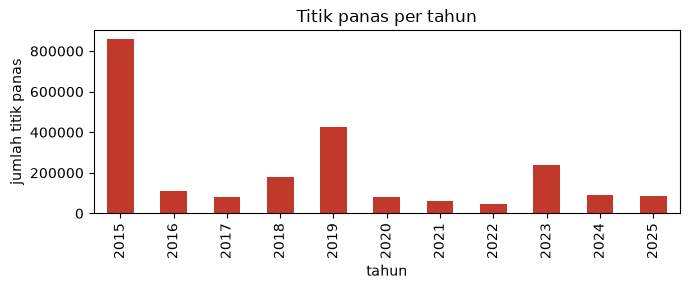

In [18]:
tren = con.execute("""
SELECT d.tahun, count(*) AS n_titik, count(*) FILTER (WHERE kepercayaan='tinggi') AS n_tinggi,
       round(avg(frp),2) AS frp_rata
FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal) GROUP BY ALL ORDER BY 1""").df()
tren["x_median"] = (tren["n_titik"] / tren["n_titik"].median()).round(2)
display(tren)
ax = tren.plot.bar(x="tahun", y="n_titik", legend=False, figsize=(7, 3), color="#c0392b")
ax.set_ylabel("jumlah titik panas"); ax.set_title("Titik panas per tahun"); plt.tight_layout(); plt.show()

### Insight 2 — Musiman: bulan paling rawan
*Pertanyaan:* di bulan apa titik panas memuncak, dan apakah pola itu sama di semua provinsi? Hanya bulan penuh per tahun yang dibandingkan, jadi cukup rata-rata antar tahun.

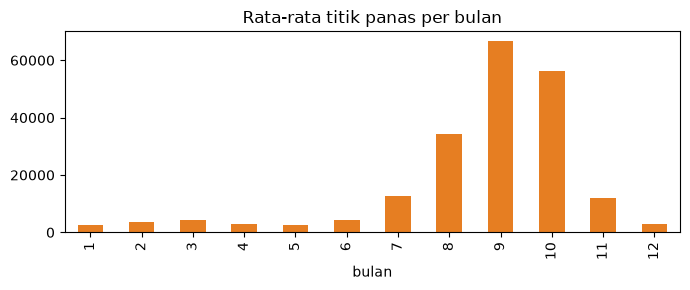

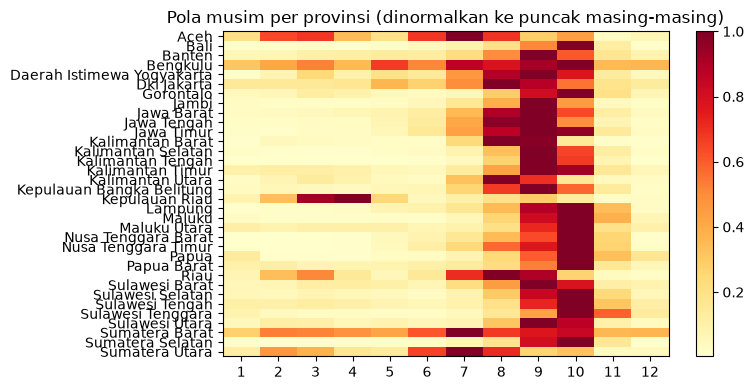

In [19]:
musim = con.execute("""
SELECT bulan, round(avg(n),0) AS rata_titik FROM (SELECT tahun, bulan, sum(n_titik) n FROM fact_wilayah_bulan GROUP BY ALL)
GROUP BY bulan ORDER BY bulan""").df()
ax = musim.plot.bar(x="bulan", y="rata_titik", legend=False, figsize=(7, 3), color="#e67e22")
ax.set_title("Rata-rata titik panas per bulan"); plt.tight_layout(); plt.show()

heat = con.execute("SELECT provinsi, bulan, sum(n_titik) n FROM v_provinsi_bulan GROUP BY ALL").df().pivot(index="provinsi", columns="bulan", values="n").fillna(0)
heat_n = heat.div(heat.max(axis=1).replace(0, np.nan), axis=0)       # tiap provinsi dinormalkan ke puncaknya sendiri
fig, ax = plt.subplots(figsize=(8, 4)); im = ax.imshow(heat_n.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(heat_n))); ax.set_yticklabels(heat_n.index); ax.set_xticks(range(12)); ax.set_xticklabels(range(1, 13))
ax.set_title("Pola musim per provinsi (dinormalkan ke puncak masing-masing)"); plt.colorbar(im); plt.tight_layout(); plt.show()

### Insight 3 — Wilayah teratas & konsentrasi (prinsip Pareto)
*Pertanyaan:* berapa persen titik panas berasal dari 10 kabupaten teratas? Kalau konsentrasinya tinggi, sumber daya pencegahan bisa difokuskan.

In [20]:
top = con.execute("""
SELECT w.kabupaten, w.provinsi, sum(n_titik) AS n_titik
FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL ORDER BY n_titik DESC""").df()
top["pct_kumulatif"] = (top["n_titik"].cumsum() / top["n_titik"].sum() * 100).round(1)
print(f"10 kabupaten teratas = {top['pct_kumulatif'].iloc[9]}% dari seluruh titik panas ({len(top)} kabupaten)")
display(top.head(10))

10 kabupaten teratas = 31.5% dari seluruh titik panas (515 kabupaten)


,kabupaten,provinsi,n_titik,pct_kumulatif
0,Ogan Komering Ilir,Sumatera Selatan,147591.0,6.6
1,Merauke,Papua,133883.0,12.5
2,Pulang Pisau,Kalimantan Tengah,83078.0,16.2
3,Ketapang,Kalimantan Barat,77343.0,19.6
4,Musi Banyuasin,Sumatera Selatan,52477.0,21.9
5,Kotawaringin Timur,Kalimantan Tengah,49107.0,24.1
6,Kapuas,Kalimantan Tengah,48375.0,26.3
7,Seruyan,Kalimantan Tengah,46708.0,28.3
8,Sumba Timur,Nusa Tenggara Timur,36977.0,30.0
9,Kutai Timur,Kalimantan Timur,34786.0,31.5


### Insight 4 — Awal & akhir musim per provinsi
*Pertanyaan:* kapan 10% dan 90% titik panas tahunan sebuah provinsi terkumpul? Hanya provinsi dengan ≥ `AMBANG_ONSET` titik per tahun yang dihitung; pada provinsi dengan titik sedikit, tanggal ini tidak bermakna. Bergesernya tanggal-tanggal ini antar tahun = peringatan dini yang bisa dipakai penyusunan jadwal siaga.

In [21]:
onset = con.execute("SELECT * FROM v_onset_musim ORDER BY provinsi, tahun").df()
onset["panjang_hari"] = (pd.to_datetime(onset["akhir_musim"]) - pd.to_datetime(onset["mulai_musim"])).dt.days
display(onset.groupby("provinsi")[["panjang_hari"]].agg(["mean", "min", "max"]).round(0).head(8))

panjang_hari          
                    mean  min  max
provinsi                          
Aceh               202.0  130  255
Banten             163.0  163  163
Bengkulu           220.0  186  248
Gorontalo          128.0   61  180
Jambi              178.0   53  291
Jawa Barat         110.0   95  139
Jawa Tengah         94.0   68  115
Jawa Timur         109.0   75  199

### Insight 5 — Area kronis vs sporadis
*Pertanyaan:* sel 0.5° mana yang berapi hampir setiap tahun (kronis) dibanding yang hanya sekali-sekali? Sebuah sel dihitung "berapi" pada suatu tahun bila punya ≥ `AMBANG_KRONIS` titik (bawaan 10), supaya satu titik tersasar tidak ikut dihitung. Area kronis cocok untuk intervensi struktural (pengelolaan gambut, kanal), sporadis untuk patroli saat tahun kering.

In [22]:
n_tahun = con.execute("SELECT count(DISTINCT tahun) FROM dim_tanggal").fetchone()[0]
kronis = con.execute("SELECT * FROM v_sel_kronis").df()
kronis["kelas"] = pd.cut(kronis["tahun_berapi"] / n_tahun, [0, 0.34, 0.67, 1.01], labels=["sporadis", "berulang", "kronis"])
print(kronis.groupby("kelas", observed=True).agg(n_sel=("id_sel", "count"), total_titik=("total_titik", "sum")))

          n_sel  total_titik
kelas                       
sporadis    186     131465.0
berulang    189     660729.0
kronis      346    1444071.0


### Insight 6 — Siang vs malam & tingkat kepercayaan
*Cara membaca:* hanya **perbandingan siang vs malam** yang sahih (jam lintasan satelit tetap). Titik malam cenderung dari api yang lebih besar/panas atau pembakaran yang sengaja dilakukan malam hari — sebagai petunjuk, bukan bukti. Makna `kepercayaan` berbeda antar wilayah, jadi dipakai untuk menyaring, bukan sebagai "kebenaran".

In [23]:
display(con.execute("""
SELECT siang_malam, kepercayaan, count(*) n, round(avg(frp),2) frp_rata
FROM fact_hotspot GROUP BY ALL ORDER BY 1, 2""").df())

,siang_malam,kepercayaan,n,frp_rata
0,malam,nominal,703335,3.04
1,malam,tinggi,10169,23.40
2,siang,nominal,1328620,9.44
3,siang,rendah,144894,12.12
4,siang,tinggi,65948,23.07


### Insight 7 — Intensitas api (FRP)
*Peringatan:* FRP VIIRS dapat dipercaya terutama untuk api kecil–menengah; api sangat besar bisa jenuh. Perlakukan sebagai indikator relatif, bukan ukuran emisi yang tepat.

FRP median / P90 / P99 (MW): [4.61, 16.06, 62.86]


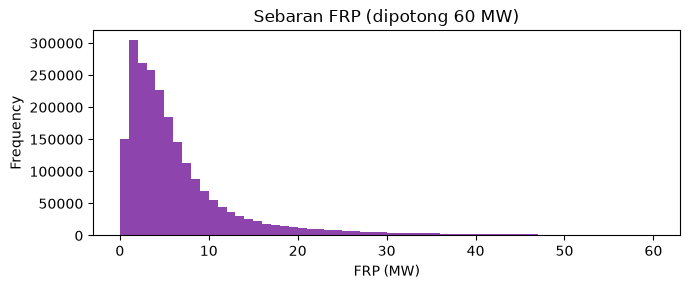

In [24]:
q = con.execute("SELECT quantile_cont(frp,[0.5,0.9,0.99]) FROM fact_hotspot").fetchone()[0]
print("FRP median / P90 / P99 (MW):", [round(x, 2) for x in q])
ax = con.execute("SELECT frp FROM fact_hotspot WHERE frp < 60").df()["frp"].plot.hist(bins=60, figsize=(7, 3), color="#8e44ad")
ax.set_xlabel("FRP (MW)"); ax.set_title("Sebaran FRP (dipotong 60 MW)"); plt.tight_layout(); plt.show()

### Insight 8 — Hari-hari ekstrem
*Pertanyaan:* tanggal mana yang jumlah titiknya jauh melampaui hari biasa? Dasarnya skor-z robust (median & MAD), tahan terhadap pencilan.

In [25]:
harian = con.execute("SELECT tanggal, count(*) n FROM fact_hotspot GROUP BY 1 ORDER BY 1").df()
med = harian["n"].rolling(61, center=True, min_periods=15).median()
mad = (harian["n"] - med).abs().rolling(61, center=True, min_periods=15).median().replace(0, np.nan)
harian["z_robust"] = 0.6745 * (harian["n"] - med) / mad
display(harian.sort_values("z_robust", ascending=False).head(8))

,tanggal,n,z_robust
3552,2024-10-26,1376,13.812587
2249,2021-02-27,799,12.296654
2248,2021-02-26,689,11.260403
1538,2019-03-19,1243,10.524184
3553,2024-10-27,1077,10.086128
2144,2020-11-14,683,9.515919
3554,2024-10-28,1023,9.459060
3882,2025-09-24,3330,9.330583


### Insight 9 — Keterkaitan titik panas dengan luas terbakar (opsional)
Bila `fact_luas_kebakaran` terisi (SiPongi), hitung rasio luas per titik panas: nilai yang jauh berbeda antar provinsi menunjukkan perbedaan jenis lahan atau cakupan deteksi.

In [26]:
n_luas = con.execute("SELECT count(*) FROM fact_luas_kebakaran").fetchone()[0]
if n_luas:
    display(con.execute("""
    SELECT l.tahun, l.provinsi, l.luas_ha, v.n_titik, round(l.luas_ha / nullif(v.n_titik,0), 1) AS ha_per_titik
    FROM fact_luas_kebakaran l JOIN (SELECT provinsi, tahun, sum(n_titik) n_titik FROM v_provinsi_bulan GROUP BY ALL) v
      ON v.provinsi = l.provinsi AND v.tahun = l.tahun ORDER BY ha_per_titik DESC""").df().head(10))
else:
    print("fact_luas_kebakaran kosong — isi dari karhutla/raw/sipongi/luas.csv (tahun,provinsi,luas_ha) untuk insight ini.")

,tahun,provinsi,luas_ha,n_titik,ha_per_titik
0,2023,Papua Barat,154798.37,476.0,325.2
1,2019,Papua Barat,108110.00,642.0,168.4
2,2024,Papua Barat,28291.96,240.0,117.9
3,2021,Papua Barat,15979.00,211.0,75.7
4,2020,Papua Barat,28277.00,661.0,42.8
5,2022,Papua Barat,8336.00,294.0,28.4
6,2021,Nusa Tenggara Barat,101173.00,5231.0,19.3
7,2022,Lampung,7989.00,477.0,16.7
8,2022,Maluku,14954.00,1044.0,14.3
9,2021,Nusa Tenggara Timur,137343.00,11155.0,12.3


## Tahap 5 — Modelling
Tiga model dengan tujuan berbeda. Semua pembagian data **berdasarkan waktu** (bukan acak) agar tidak "mengintip masa depan".

### 5A. Klaster spasial titik panas (DBSCAN)
Menemukan "gugus api" yang padat. Jarak dihitung haversine (radian); `eps` = 10 km, minimal `MIN_SAMPEL_DBSCAN` titik. Dijalankan per tahun pada musim puncak (Agu–Okt), dengan titik berkepercayaan bukan-rendah.

**Catatan sampel:** bila titik per tahun melebihi `CAP_DBSCAN`, diambil sampel acak. Agar kriteria kepadatan tetap setara antar tahun, `min_samples` diskalakan dengan rasio sampel, dan ukuran klaster (`n_titik`, `frp_sum`) dibagi rasio itu menjadi **perkiraan**; jumlah sebenarnya di sampel disimpan di `n_sampel`.

In [27]:
from sklearn.cluster import DBSCAN
KM_BUMI = 6371.0088
hasil_cluster = []
pts = con.execute("""SELECT d.tahun, f.latitude, f.longitude, f.frp FROM fact_hotspot f JOIN dim_tanggal d USING (tanggal)
                     WHERE f.kepercayaan <> 'rendah' AND d.bulan BETWEEN 8 AND 10""").df()
for th, g in pts.groupby("tahun"):
    n_all = len(g)
    if n_all > CAP_DBSCAN: g = g.sample(CAP_DBSCAN, random_state=SEED)
    rasio = len(g) / n_all
    ms = max(5, int(round(MIN_SAMPEL_DBSCAN * rasio)))                      # jaga kepadatan minimal tetap setara antar tahun
    lab = DBSCAN(eps=10 / KM_BUMI, min_samples=ms, metric="haversine", algorithm="ball_tree").fit_predict(np.radians(g[["latitude", "longitude"]]))
    g = g.assign(cluster=lab); g = g[g["cluster"] >= 0]
    r = g.groupby("cluster").agg(n_sampel=("frp", "size"), frp_sampel=("frp", "sum"), lat=("latitude", "mean"), lon=("longitude", "mean")).reset_index()
    r["n_titik"] = r["n_sampel"] / rasio; r["frp_sum"] = r["frp_sampel"] / rasio; r["rasio_sampel"] = rasio
    r.insert(0, "tahun", th); hasil_cluster.append(r.drop(columns="frp_sampel"))
hasil_cluster = pd.concat(hasil_cluster, ignore_index=True)
# beri nama daerah (kabupaten terdekat dari pusat klaster) agar mudah dipahami orang awam
_cp = gpd.GeoDataFrame(hasil_cluster[["lat", "lon"]], geometry=gpd.points_from_xy(hasil_cluster["lon"], hasil_cluster["lat"]), crs=4326).to_crs(3395)
_cw = gpd.sjoin_nearest(_cp, batas.to_crs(3395)[["wadmkk", "wadmpr", "geometry"]], how="left")
_cw = _cw[~_cw.index.duplicated(keep="first")]
hasil_cluster["kabupaten"] = _cw["wadmkk"].to_numpy(); hasil_cluster["provinsi"] = _cw["wadmpr"].to_numpy()
print(f"{len(hasil_cluster)} klaster | per tahun:", hasil_cluster.groupby("tahun").size().to_dict())
print("rasio sampel per tahun:", hasil_cluster.groupby("tahun")["rasio_sampel"].first().round(2).to_dict())
display(hasil_cluster.sort_values("n_titik", ascending=False).head(5))
con.register("hc_df", hasil_cluster); _ = con.execute("CREATE OR REPLACE TABLE hasil_cluster AS SELECT * FROM hc_df")

2797 klaster | per tahun: {2015: 287, 2016: 269, 2017: 268, 2018: 329, 2019: 287, 2020: 208, 2021: 195, 2022: 152, 2023: 275, 2024: 297, 2025: 230}
rasio sampel per tahun: {2015: 0.58, 2016: 1.0, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0, 2025: 1.0}


,tahun,cluster,n_sampel,lat,lon,n_titik,frp_sum,rasio_sampel,kabupaten,provinsi
2,2015,2,180855,-2.155342,113.531461,311659.735163,2.300339e+06,0.580296,Katingan,Kalimantan Tengah
1,2015,1,117619,-2.571002,104.525755,202687.823893,1.742247e+06,0.580296,Banyu Asin,Sumatera Selatan
1154,2019,1,81759,-2.581311,113.886991,81759.000000,5.930873e+05,1.000000,Pulang Pisau,Kalimantan Tengah
1171,2019,18,69882,-2.561012,104.399579,69882.000000,6.763808e+05,1.000000,Banyu Asin,Sumatera Selatan
5,2015,5,26439,-7.549072,139.578687,45561.205042,4.031309e+05,0.580296,Merauke,Papua


### 5B. Tipologi kabupaten (K-Means)
Mengelompokkan kabupaten berdasarkan **ciri**: tingkat rata-rata, kekerapan antar tahun, ketajaman musim, porsi malam, intensitas. Hasilnya label tipologi yang mudah dibaca (mis. "kronis & intens" vs "sporadis"). Skor siluet dilaporkan untuk beberapa K, tetapi jumlah tipologi diambil dari `K_TIPOLOGI` (bawaan 4) supaya hasilnya cukup rinci untuk dibaca; K=2 biasanya hanya memisahkan "tinggi" dan "rendah".

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

fw = con.execute("""
SELECT w.wilayah_id, w.kabupaten, w.provinsi, f.tahun, f.bulan, f.n_titik, f.n_malam, f.frp_sum
FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id)""").df()
tahunan = fw.groupby(["wilayah_id", "tahun"])["n_titik"].sum().unstack(fill_value=0)
ciri = pd.DataFrame({
    "log_rata_tahunan": np.log1p(tahunan.mean(axis=1)),
    "variasi_antar_tahun": tahunan.std(axis=1) / tahunan.mean(axis=1).replace(0, np.nan),
    "porsi_tahun_berapi": (tahunan > 10).mean(axis=1),
})
ciri["porsi_agu_okt"] = (fw[fw["bulan"].between(8, 10)].groupby("wilayah_id")["n_titik"].sum() / fw.groupby("wilayah_id")["n_titik"].sum())
ciri["porsi_malam"] = fw.groupby("wilayah_id")["n_malam"].sum() / fw.groupby("wilayah_id")["n_titik"].sum()
ciri["frp_per_titik"] = fw.groupby("wilayah_id")["frp_sum"].sum() / fw.groupby("wilayah_id")["n_titik"].sum()
ciri = ciri.fillna(0)
X = StandardScaler().fit_transform(ciri)
sk = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=SEED).fit_predict(X)) for k in range(2, 7)}
K = K_TIPOLOGI; print("silhouette:", {k: round(v, 3) for k, v in sk.items()}, "| K dipakai =", K, "(parameter K_TIPOLOGI)")
ciri["klaster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(X)

# Nama klaster otomatis dari peringkat tingkat rata-rata & kekerapan (periksa & ubah manual sesuai konteks!)
ring = ciri.groupby("klaster")[["log_rata_tahunan", "porsi_tahun_berapi"]].mean()
urut = ring["log_rata_tahunan"].rank(ascending=False).astype(int)
NAMA_TINGKAT = ["Rawan tinggi", "Rawan sedang", "Rawan rendah", "Jarang terbakar"]          # bahasa awam untuk dashboard
nama = {k: (NAMA_TINGKAT[int(urut[k]) - 1] if K == 4 else f"Tingkat {int(urut[k])} dari {K}") for k in ring.index}
ciri["tipologi"] = ciri["klaster"].map(nama)
hasil_tipologi = ciri.reset_index().merge(fw[["wilayah_id", "kabupaten", "provinsi"]].drop_duplicates(), on="wilayah_id")
display(hasil_tipologi.groupby("tipologi")[list(ciri.columns[:6])].mean().round(2))
con.register("ht_df", hasil_tipologi); _ = con.execute("CREATE OR REPLACE TABLE hasil_tipologi AS SELECT * FROM ht_df")

silhouette: {2: 0.325, 3: 0.235, 4: 0.218, 5: 0.232, 6: 0.24} | K dipakai = 4 (parameter K_TIPOLOGI)


,log_rata_tahunan,variasi_antar_tahun,porsi_tahun_berapi,porsi_agu_okt,porsi_malam,frp_per_titik
tipologi,,,,,,
Jarang terbakar,1.60,1.49,0.15,0.58,0.25,4.25
Rawan rendah,4.33,0.82,0.89,0.69,0.32,4.23
Rawan sedang,5.03,0.76,0.95,0.51,0.10,7.72
Rawan tinggi,6.25,1.62,0.94,0.78,0.37,7.38


### 5C. Prediksi risiko mingguan per sel 0.5° (LightGBM)
**Pertanyaan:** pada akhir minggu *t*, sel mana yang **akan punya ≥1 titik panas di minggu *t+1***? Hasilnya skor risiko untuk memprioritaskan patroli.

**Fitur** (semuanya hanya memakai informasi sampai akhir minggu *t*): jumlah titik 1/2/4/8/26 minggu terakhir, rata-rata FRP & porsi kepercayaan-tinggi/malam 4 minggu, minggu sejak api terakhir, musim (sin/cos minggu ke-*t+1*), posisi sel, dan hujan bila tersedia.
**Periode model:** mulai `MODEL_AWAL` (bawaan 2019, mengikuti data hujan); bagian lain notebook memakai seluruh riwayat.
**Pembagian waktu:** latih sampai `TAHUN_VAL-1`, validasi `TAHUN_VAL` (early stopping & kalibrasi), uji `TAHUN_UJI`.
**Pembanding wajib:** *persistence* (minggu depan = minggu ini) dan *klimatologi* (rata-rata historis sel pada minggu-tahun yang sama). Model hanya berguna jika mengalahkan keduanya.

In [29]:
df = con.execute("SELECT * FROM fact_sel_minggu ORDER BY id_sel, minggu_mulai").df()
df["minggu_mulai"] = pd.to_datetime(df["minggu_mulai"])
g = df.groupby("id_sel")

def jumlah_geser(kolom, w):           # jumlah w minggu terakhir (termasuk minggu t), vektorisasi via cumsum
    cs = g[kolom].cumsum()
    return cs - cs.groupby(df["id_sel"]).shift(w).fillna(0)

for w in (1, 2, 4, 8, 26):
    df[f"n_{w}m"] = jumlah_geser("n_titik", w)
n4 = df["n_4m"].replace(0, np.nan)
df["frp_rata_4m"] = (jumlah_geser("frp_sum", 4) / n4).fillna(0)
df["porsi_tinggi_4m"] = (jumlah_geser("n_tinggi", 4) / n4).fillna(0)
df["porsi_malam_4m"] = (jumlah_geser("n_malam", 4) / n4).fillna(0)
k = g.cumcount(); terakhir = k.where(df["n_titik"] > 0).groupby(df["id_sel"]).ffill()
df["minggu_sejak_api"] = (k - terakhir).fillna(99)

sel = con.execute("SELECT * FROM dim_sel").df()
df = df.merge(sel, on="id_sel")
df["minggu_target"] = df["minggu_mulai"] + pd.Timedelta(days=7)
woy = df["minggu_target"].dt.isocalendar().week.astype(int)
df["woy_target"] = woy
df["sin_musim"], df["cos_musim"] = np.sin(2 * np.pi * woy / 52), np.cos(2 * np.pi * woy / 52)
df["y"] = (g["n_titik"].shift(-1).reindex(df.index) > 0).astype(float)          # target: ada api minggu depan
df.loc[g["n_titik"].shift(-1).reindex(df.index).isna(), "y"] = np.nan
df = df.dropna(subset=["y"]).copy(); df["y"] = df["y"].astype(int)

# --- hujan bulanan opsional (hujan_bulanan.parquet: id_sel, tahun, bulan, hujan_mm).
# Hanya bulan yang SUDAH SELESAI sebelum minggu t yang dipakai (tidak mengintip hari setelah minggu t):
#   hujan_1bln = hujan bulan sebelum bulan minggu t; hujan_3bln = jumlah 3 bulan sebelumnya.
FITUR = ["n_1m", "n_2m", "n_4m", "n_8m", "n_26m", "frp_rata_4m", "porsi_tinggi_4m", "porsi_malam_4m",
         "minggu_sejak_api", "sin_musim", "cos_musim", "lat_tengah", "lon_tengah"]
f_hujan = RAW/"hujan"/"hujan_bulanan.parquet"
PAKAI_HUJAN = False
if f_hujan.exists():
    h = pd.read_parquet(f_hujan)
    h["p"] = pd.to_datetime(dict(year=h["tahun"], month=h["bulan"], day=1)).dt.to_period("M")
    lebar = h.pivot_table(index="p", columns="id_sel", values="hujan_mm", aggfunc="mean")
    lebar = lebar.reindex(pd.period_range(lebar.index.min(), lebar.index.max(), freq="M"))       # bulan yang hilang → NaN
    h3 = lebar.rolling(3, min_periods=3).sum()
    a1 = lebar.stack().rename("hujan_1bln").reset_index(); a1.columns = ["pm", "id_sel", "hujan_1bln"]
    a3 = h3.stack().rename("hujan_3bln").reset_index(); a3.columns = ["pm", "id_sel", "hujan_3bln"]
    df["pm"] = df["minggu_mulai"].dt.to_period("M") - 1                                          # bulan terakhir yang sudah selesai
    df = df.merge(a1, on=["pm", "id_sel"], how="left").merge(a3, on=["pm", "id_sel"], how="left").drop(columns="pm")
    FITUR += ["hujan_1bln", "hujan_3bln"]; PAKAI_HUJAN = True
    print(f"fitur hujan dipakai | tercakup: {df['hujan_3bln'].notna().mean():.0%} baris (sisanya NaN, ditangani LightGBM)")
else:
    print("hujan tidak ada → model tanpa fitur hujan (hasil biasanya lebih lemah di musim kering awal)")

# --- batasi MODEL ke periode MODEL_AWAL dst. (fitur riwayat di atas sudah dihitung dari seluruh data, jadi awal 2019 tidak "kekurangan" riwayat)
n_sebelum = len(df)
df = df[df["minggu_mulai"] >= pd.Timestamp(MODEL_AWAL)].copy()
print(f"periode model: {df['minggu_mulai'].min().date()} → {df['minggu_mulai'].max().date()} | baris {n_sebelum:,} → {len(df):,}")
if PAKAI_HUJAN:
    cakup = df.groupby(df["minggu_target"].dt.year)["hujan_3bln"].apply(lambda s: s.notna().mean()).round(2)
    print("cakupan fitur hujan per tahun:", cakup.to_dict())
    kurang = [int(t) for t in (TAHUN_VAL, TAHUN_UJI) if cakup.get(t, 0) < 0.8]
    if kurang: print(f"PERINGATAN: tahun {kurang} punya data hujan < 80% — lengkapi berkas hujan atau hasil model tidak bisa dipercaya")

th = df["minggu_target"].dt.year
latih, valid, uji = df[th < TAHUN_VAL], df[th == TAHUN_VAL], df[th == TAHUN_UJI]
print(f"baris latih/valid/uji: {len(latih):,} / {len(valid):,} / {len(uji):,} | prevalensi positif uji: {uji['y'].mean():.3f}")

fitur hujan dipakai | tercakup: 63% baris (sisanya NaN, ditangani LightGBM)
periode model: 2019-01-07 → 2025-12-15 | baris 590,876 → 374,979
cakupan fitur hujan per tahun: {2019: 1.0, 2020: 1.0, 2021: 1.0, 2022: 1.0, 2023: 1.0, 2024: 1.0, 2025: 1.0}
baris latih/valid/uji: 267,547 / 54,749 / 52,683 | prevalensi positif uji: 0.206


In [30]:
import lightgbm as lgb
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.isotonic import IsotonicRegression
rng = np.random.default_rng(SEED)
K10 = max(1, int(0.10 * df["id_sel"].nunique()))          # "10% sel teratas" (bukan K=50 tetap, yang dibatasi jumlah sel berapi)

def _per_minggu(data, skor):
    d = data[["minggu_target", "y"]].assign(s=skor + rng.uniform(0, 1e-9, len(data)))       # pemecah seri acak
    return [x for _, x in d.groupby("minggu_target") if x["y"].sum() > 0]                     # hanya minggu yang ada sel berapi

def recall_at_k(data, skor, K):
    """Per minggu: dari semua sel yang benar-benar berapi, berapa % tertangkap di K sel skor tertinggi. Rata-rata antar minggu."""
    return float(np.mean([x.nlargest(K, "s")["y"].sum() / x["y"].sum() for x in _per_minggu(data, skor)]))

def presisi_at_k(data, skor, K):
    """Per minggu: dari K sel skor tertinggi, berapa % yang benar-benar berapi. Rata-rata antar minggu."""
    return float(np.mean([x.nlargest(K, "s")["y"].mean() for x in _per_minggu(data, skor)]))

def latih_evaluasi(thn_uji):
    """Latih sampai thn_uji-2, validasi thn_uji-1, uji thn_uji. Mengembalikan tabel metrik + objek model."""
    thn_val = thn_uji - 1
    th = df["minggu_target"].dt.year
    latih, valid, uji = df[th < thn_val], df[th == thn_val], df[th == thn_uji]
    if min(len(latih), len(valid), len(uji)) == 0 or latih["y"].sum() == 0:
        return None, None
    persist = uji["n_1m"].to_numpy(float)
    klim_tab = latih.groupby(["id_sel", "woy_target"])["y"].mean()
    klim = np.nan_to_num(uji.set_index(["id_sel", "woy_target"]).index.map(klim_tab).to_numpy(dtype=float), nan=0.0)
    model = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.05, num_leaves=31, min_child_samples=40,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
    model.fit(latih[FITUR], latih["y"], eval_set=[(valid[FITUR], valid["y"])], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(40, verbose=False)])
    iso = IsotonicRegression(out_of_bounds="clip").fit(model.predict_proba(valid[FITUR])[:, 1], valid["y"])   # kalibrasi pada validasi
    p_uji = model.predict_proba(uji[FITUR])[:, 1]; p_kal = iso.predict(p_uji)
    p0 = uji["y"].mean(); ref = p0 * (1 - p0)                       # Brier "tanpa kemampuan" (selalu menebak prevalensi)
    def baris(nama, skor, prob):
        b = brier_score_loss(uji["y"], skor) if prob else np.nan
        return dict(tahun_uji=thn_uji, model=nama, pr_auc=average_precision_score(uji["y"], skor),
                    recall_10persen_sel=recall_at_k(uji, skor, K10), presisi_at_50=presisi_at_k(uji, skor, 50),
                    brier=b, bss=(1 - b / ref) if prob else np.nan, prevalensi_uji=p0)
    tabel = pd.DataFrame([baris("Persistence", persist, False), baris("Klimatologi", klim, True),
                          baris("LightGBM", p_uji, True), baris("LightGBM + kalibrasi", p_kal, True)]).round(4)
    return tabel, dict(model=model, uji=uji, p_kal=p_kal, pohon=model.best_iteration_)

**Evaluasi di data uji.** Metrik:
* **PR-AUC** (kelas positif jarang) — acak ≈ prevalensi;
* **recall pada 10% sel teratas** dan **presisi@50** per minggu. (Recall@50 tidak dipakai: pada minggu puncak ratusan sel berapi, sehingga 50 sel tak mungkin menangkap semuanya, dan angkanya dibatasi oleh K, bukan oleh kualitas model);
* **Brier** dan **BSS** (*Brier skill score* = 1 − Brier/Brier-acuan; 0 = tak lebih baik dari menebak prevalensi, 1 = sempurna).

Tahun uji utama = `TAHUN_UJI`. Tahun-tahun di `TAHUN_UJI_EKSTRA` dievaluasi juga (latih ulang) agar terlihat kinerja pada **tahun ekstrem**, bukan hanya tahun biasa.
*Catatan:* sel dipilih dengan data sampai `TAHUN_VAL-1`; untuk tahun uji ekstra yang lebih awal, ada sedikit informasi masa depan dalam pemilihan sel, jadi hasilnya perkiraan.

In [31]:
hasil_utama, obj = latih_evaluasi(TAHUN_UJI)
model, uji, p_kal = obj["model"], obj["uji"], obj["p_kal"]
print("tahun uji utama:", TAHUN_UJI, "| pohon terpakai:", obj["pohon"], "| baris uji:", f"{len(uji):,}", "| K10 =", K10)
ekstra = []
for t in TAHUN_UJI_EKSTRA:
    if t == TAHUN_UJI: continue
    tb, _ = latih_evaluasi(t)
    if tb is not None: ekstra.append(tb)
hasil_evaluasi = pd.concat([hasil_utama] + ekstra, ignore_index=True)
display(hasil_evaluasi)
_ = con.register("he_df", hasil_evaluasi); _ = con.execute("CREATE OR REPLACE TABLE hasil_evaluasi AS SELECT * FROM he_df")

tahun uji utama: 2025 | pohon terpakai: 382 | baris uji: 52,683 | K10 = 103


,tahun_uji,model,pr_auc,recall_10persen_sel,presisi_at_50,brier,bss,prevalensi_uji
0,2025,Persistence,0.5007,0.2957,0.6392,NaN,NaN,0.2055
1,2025,Klimatologi,0.5308,0.2857,0.5718,0.1305,0.2006,0.2055
2,2025,LightGBM,0.6741,0.3438,0.6988,0.1055,0.3537,0.2055
3,2025,LightGBM + kalibrasi,0.6660,0.3426,0.6996,0.1055,0.3536,0.2055
4,2023,Persistence,0.6726,0.2542,0.7369,NaN,NaN,0.2930
5,2023,Klimatologi,0.5941,0.2303,0.6577,0.1592,0.2315,0.2930
6,2023,LightGBM,0.8041,0.2833,0.7831,0.1154,0.4430,0.2930
7,2023,LightGBM + kalibrasi,0.7963,0.2825,0.7815,0.1178,0.4311,0.2930


**Cara membaca:** bila LightGBM tidak jelas lebih baik dari klimatologi/persistence (PR-AUC dan BSS), jangan dipakai untuk keputusan — kembali ke fitur (tambah hujan, kondisi gambut) atau pakai klimatologi saja. Bandingkan baris tahun uji biasa dengan tahun ekstrem. Skor kalibrasi bisa bernilai tepat 1,0 di ujung atas (batas isotonic regression); jangan ditafsirkan sebagai kepastian. Skor ini **bukan peringatan resmi**.

**Penjelasan fitur (SHAP)** — fitur mana yang paling mendorong skor:

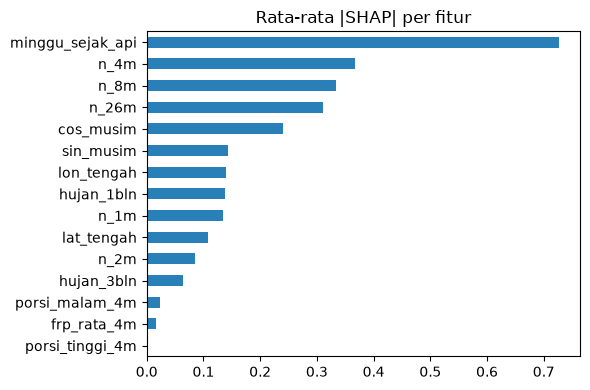

In [32]:
try:
    import shap
    contoh = uji[FITUR].sample(min(2000, len(uji)), random_state=SEED)
    sv = shap.TreeExplainer(model).shap_values(contoh)
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv); sv = sv[..., 1] if sv.ndim == 3 else sv
    pent = pd.Series(np.abs(sv).mean(0), index=FITUR).sort_values()
    pent.plot.barh(figsize=(6, 4), color="#2980b9", title="Rata-rata |SHAP| per fitur"); plt.tight_layout(); plt.show()
except Exception as e:
    print("SHAP dilewati:", e); pd.Series(model.feature_importances_, index=FITUR).sort_values().plot.barh(figsize=(6, 4)); plt.show()

Simpan skor risiko periode uji ke gudang data (dipakai dashboard):

In [33]:
risiko = uji[["id_sel", "minggu_target", "lat_tengah", "lon_tengah", "y"]].copy()
risiko["skor"] = p_kal.round(4)
con.register("risiko_df", risiko); _ = con.execute("CREATE OR REPLACE TABLE risiko_mingguan AS SELECT * FROM risiko_df")
print(risiko.groupby("minggu_target")["skor"].max().sort_values(ascending=False).head(3))

minggu_target
2025-08-25    1.0
2025-08-18    1.0
2025-08-11    1.0
Name: skor, dtype: float64


### 5D. (Opsional) Perkiraan deret waktu bulanan — SARIMA
Untuk satu provinsi atau nasional. Dengan hanya beberapa tahun data, hasilnya kasar; gunakan sebagai pembanding, bukan dasar keputusan.

In [34]:
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
except ImportError:
    SARIMAX = None; print("statsmodels belum terpasang → jalankan: %pip install statsmodels  (bagian ini opsional)")
if SARIMAX is not None:
    bulanan = con.execute("SELECT make_date(tahun, bulan, 1) AS t, sum(n_titik) AS n FROM fact_wilayah_bulan GROUP BY 1 ORDER BY 1").df().set_index("t")["n"]
    bulanan.index = pd.DatetimeIndex(bulanan.index, freq="MS")
    latih_s, uji_s = bulanan.iloc[:-12], bulanan.iloc[-12:]
    m = SARIMAX(np.log1p(latih_s), order=(1, 0, 1), seasonal_order=(1, 1, 0, 12), enforce_stationarity=False).fit(disp=False)
    pred = np.expm1(m.forecast(12)).clip(lower=0)
    mae_s = float(np.abs(pred.values - uji_s.values).mean()); mae_naif = float(np.abs(latih_s.iloc[-12:].values - uji_s.values).mean())
    print(f"MAE SARIMA: {mae_s:,.0f} | MAE naif (tahun lalu): {mae_naif:,.0f}  →", "SARIMA lebih baik" if mae_s < mae_naif else "SARIMA TIDAK lebih baik dari naif (hasil negatif; laporkan apa adanya)")

MAE SARIMA: 4,442 | MAE naif (tahun lalu): 3,620  → SARIMA TIDAK lebih baik dari naif (hasil negatif; laporkan apa adanya)


## Tahap 6 — Dashboard (Streamlit), bahasa awam
Dashboard **tidak** membaca jutaan baris mentah. Notebook mengekspor **tabel agregat kecil** ke `dashboard/data/*.parquet`; `app.py` hanya membaca berkas itu. Cepat, ringan, dan aman di-*deploy*.

Prinsip desainnya: **kalimat temuan dibuat otomatis** dari data (bukan angka mentah saja), istilah teknis diganti bahasa sehari-hari, setiap hasil model diberi **nama daerah**, dan rincian teknis disembunyikan di bagian "untuk yang ingin tahu lebih detail".

### 6.1 Ekspor agregat

In [35]:
# nama daerah untuk setiap sel model (kabupaten terdekat dari titik tengah sel)
_sel = con.execute("SELECT id_sel, lat_tengah, lon_tengah FROM dim_sel").df()
_pt = gpd.GeoDataFrame(_sel, geometry=gpd.points_from_xy(_sel["lon_tengah"], _sel["lat_tengah"]), crs=4326).to_crs(3395)
_sw = gpd.sjoin_nearest(_pt, batas.to_crs(3395)[["wadmkk", "wadmpr", "geometry"]], how="left")
_sw = _sw[~_sw.index.duplicated(keep="first")]
sel_wilayah = _sw[["id_sel", "wadmkk", "wadmpr"]].rename(columns={"wadmkk": "kabupaten", "wadmpr": "provinsi"})
_ = con.register("sel_wilayah_df", sel_wilayah); _ = con.execute("CREATE OR REPLACE TABLE sel_wilayah AS SELECT * FROM sel_wilayah_df")

def ekspor(nama, sql):
    out = DASH/"data"/f"{nama}.parquet"
    df_ = con.execute(sql).df()
    df_.to_parquet(out, index=False)
    return nama, len(df_), round(out.stat().st_size / 1024, 1)

import json
(DASH/"data"/"meta.json").write_text(json.dumps({"pakai_hujan": bool(PAKAI_HUJAN), "model_awal": MODEL_AWAL[:4]}))
res_ekspor = [
 ekspor("prov_bulan", "SELECT * FROM v_provinsi_bulan"),
 ekspor("kab_tahun", """SELECT w.kdpkab, w.kabupaten, w.provinsi, f.tahun, sum(n_titik) AS n_titik, sum(n_tinggi) AS n_tinggi,
                         sum(n_malam) AS n_malam, sum(frp_sum) AS frp_sum
                         FROM fact_wilayah_bulan f JOIN dim_wilayah w USING (wilayah_id) GROUP BY ALL"""),
 ekspor("grid_bulan", f"""SELECT id_sel_01 AS id_sel, tahun, bulan, n_titik, round(frp_sum,1) AS frp_sum,
                         (id_sel_01 // 10000 - 200 + 0.5) * {RES_HALUS} AS lat, (id_sel_01 % 10000 + 0.5) * {RES_HALUS} AS lon
                         FROM v_grid_bulan"""),
 ekspor("onset", "SELECT provinsi, tahun, mulai_musim, akhir_musim, total_titik FROM v_onset_musim"),
 ekspor("klaster", "SELECT * FROM hasil_cluster"),
 ekspor("tipologi", "SELECT wilayah_id, kabupaten, provinsi, tipologi, log_rata_tahunan, variasi_antar_tahun, porsi_tahun_berapi, porsi_agu_okt, porsi_malam, frp_per_titik FROM hasil_tipologi"),
 ekspor("risiko", """SELECT r.id_sel, r.minggu_target, r.lat_tengah AS lat, r.lon_tengah AS lon, r.y AS terjadi, r.skor, w.kabupaten, w.provinsi
                     FROM risiko_mingguan r LEFT JOIN sel_wilayah w USING (id_sel)"""),
 ekspor("evaluasi", "SELECT * FROM hasil_evaluasi"),
]
pd.DataFrame(res_ekspor, columns=["berkas", "baris", "KB"])

,berkas,baris,KB
0,prov_bulan,4336,61.7
1,kab_tahun,5239,92.0
2,grid_bulan,278078,1960.2
3,onset,251,9.3
4,klaster,2797,104.0
5,tipologi,515,37.3
6,risiko,52683,74.3
7,evaluasi,8,5.4


### 6.2 perbaiki luas.csv dan buat luas.parquet
`%%writefile` menulis sel ini menjadi `dashboard/app.py`.
Halaman: **Beranda · Kapan terjadi? · Di mana terjadi? · Daerah rawan · Prakiraan minggu depan · Tentang data**.

In [38]:
import pandas as pd, geopandas as gpd
from pathlib import Path

X = "luas-karhutla-provinsi.xlsx"                      # sesuaikan nama/lokasi berkas Excel SiPongi
x = pd.read_excel(X, dtype=str)
x = x[x["Kode Wilayah"].notna()].copy()
x.columns = [str(c) for c in x.columns]
x["kode"] = x["Kode Wilayah"].replace({"93": "91", "94": "91", "95": "91", "96": "92"})   # pemekaran Papua -> induk

tahun = [c for c in x.columns if c.isdigit() and int(c) <= 2024]                          # 2025 tampak belum lengkap
p = x.melt(id_vars=["kode"], value_vars=tahun, var_name="tahun", value_name="luas_ha")
p["luas_ha"] = p["luas_ha"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False).astype(float)
p["tahun"] = p["tahun"].astype(int)
p = p.groupby(["tahun", "kode"], as_index=False)["luas_ha"].sum()

b = gpd.read_file("karhutla/raw/batas/batas_kabupaten.geojson")
peta = b.assign(kode=b["kdpkab"].str[2:4]).drop_duplicates("kode").set_index("kode")["wadmpr"].to_dict()
peta["91"], peta["92"] = "Papua", "Papua Barat"       # kode SiPongi (baru) berbeda dari kode batas 2020
p["provinsi"] = p["kode"].map(peta)
print("kode tanpa nama:", p.loc[p["provinsi"].isna(), "kode"].unique())
print("nama tidak ada di batas:", sorted(set(p["provinsi"].dropna()) - set(b["wadmpr"])))
p = p.dropna(subset=["provinsi"])[["tahun", "provinsi", "luas_ha"]]

Path("karhutla/raw/sipongi").mkdir(parents=True, exist_ok=True)
p.to_csv("karhutla/raw/sipongi/luas.csv", index=False)
p.to_parquet(DASH/"data"/"luas.parquet", index=False)
print(len(p), "baris |", p["provinsi"].nunique(), "provinsi |", p["tahun"].min(), "-", p["tahun"].max())
print(p[p["provinsi"].isin(["Papua", "Papua Barat"])].pivot(index="tahun", columns="provinsi", values="luas_ha").round(0))

kode tanpa nama: <ArrowStringArray>
[]
Length: 0, dtype: str
nama tidak ada di batas: []
204 baris | 34 provinsi | 2019 - 2024
provinsi     Papua  Papua Barat
tahun                          
2019      108110.0       1533.0
2020       28277.0       5716.0
2021       15979.0         77.0
2022        8336.0       1738.0
2023      154798.0        763.0
2024       28292.0        227.0


### 6.3 Uji & jalankan
Uji tanpa membuka peramban (sebelum deploy), lalu jalankan.

In [39]:
from streamlit.testing.v1 import AppTest

app_path = (DASH/"app.py").resolve()
assert app_path.exists(), "dashboard/app.py belum ada. Taruh berkas app.py baru di folder dashboard/."
assert (DASH/"data"/"luas.parquet").exists(), "luas.parquet belum ada. Jalankan sel luas terbakar (di bawah sel 6.1) dulu."

HALAMAN = ["Beranda", "Kapan terjadi?", "Di mana terjadi?", "Luas terbakar",
           "Daerah rawan", "Prakiraan minggu depan", "Tentang data"]
for hal in HALAMAN:
    at = AppTest.from_file(str(app_path), default_timeout=60).run()
    at.sidebar.radio[0].set_value(hal).run()
    assert not at.exception, (hal, [e.value for e in at.exception])
    print("OK  ", hal)

2026-11-16 07:01:14.733 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-16 07:01:15.206 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Beranda


2026-11-16 07:01:15.676 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Kapan terjadi?


2026-11-16 07:01:16.143 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Di mana terjadi?


... (2 outputs left out)

2026-11-16 07:01:17.000 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Daerah rawan


2026-11-16 07:01:17.401 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


OK   Prakiraan minggu depan
OK   Tentang data


Jalankan dashboard dari terminal (di folder yang sama dengan notebook):

```bash
streamlit run dashboard/app.py
```

**Deploy gratis:** unggah folder `dashboard/` (berisi `app.py`, `data/`, dan `requirements.txt` berisi `streamlit pandas plotly pyarrow numpy`) ke GitHub, lalu hubungkan ke Streamlit Community Cloud. Batas sumber daya dan perilaku "tidur" aplikasi bisa berubah; cek dokumentasi resminya. Jaga ukuran `data/` kecil (puluhan MB).

## Penutup — ringkasan, batasan, dan langkah lanjut

| Hal | Catatan |
|---|---|
| Menjalankan dengan data nyata | ubah `MODE = "nyata"`, taruh CSV FIRMS & GeoJSON batas di `karhutla/raw/`, jalankan ulang dari atas. Periksa log ETL: berapa persen titik jatuh di luar wilayah? |
| Batasan inti | titik panas ≠ kebakaran; jam lintasan tetap; FRP tak andal untuk api besar; makna *confidence* bervariasi; batas wilayah berubah (pemekaran Papua) |
| Peningkatan model | tambah fitur hujan (CHIRPS, 1D), indeks El Niño/IOD sebagai penjelas, tutupan gambut; evaluasi per wilayah |
| Pembaruan rutin | unduh CSV baru → jalankan ulang Tahap 2–6 |